# Save Root System architecture into networkx

In [1]:
%run read.py

In [2]:
from pathlib import Path
from pprint import pprint

data = Path('data')/'UC1_HIRROS_arabidopsis'
rsa_files = list(data.glob('*.rsml'))
pprint(rsa_files)

json_dir = (data/'json')
json_dir.mkdir(exist_ok=True)
uc1_dir =json_dir/'UC1_HIRROS_arabidopsis'
uc1_dir.mkdir(exist_ok=True)

[PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN016.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN017.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN021.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN026.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN007.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN028.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN033.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN005.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN013.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN015.rsml')]


In [3]:
for fn in rsa_files:
    dgs = rsml2nx(fn)
    name = fn.name.split('.')[0]
    fn_js = f'{name}_%d.json'
    for i in range(len(dgs)):
        fn_json = fn_js%i
        fn_json = json_dir/fn_json
        #save_json(dgs[i], fn_json)
    

Distance to the closest point  24.331050121192877
Distance to the closest point  23.345235059857504
Distance to the closest point  34.20526275297414
Distance to the closest point  64.19501538281614
Distance to the closest point  27.294688127912362
Distance to the closest point  47.042533945356304
Distance to the closest point  23.194827009486403
Distance to the closest point  32.2490309931942
Distance to the closest point  21.0
Distance to the closest point  29.274562336608895
Distance to the closest point  26.076809620810597
Distance to the closest point  33.61547262794322
Distance to the closest point  43.46262762420146
Distance to the closest point  50.00999900019995
Distance to the closest point  21.213203435596427
Distance to the closest point  27.294688127912362


-------

# Save RootSystemTracker (RST) files into json

In [4]:
from pathlib import Path
from pprint import pprint

rsa_files = []
data = Path('data')/'RSPM_Ariadne_2025'
new_root_dir = Path('json')

for fn in data.rglob('*.rsml'):
    if not any(part.startswith('.') for part in fn.parts):
        print(fn)
        parts = fn.parts
        # Create the dir...
        my_dir = new_root_dir.joinpath(*parts[1:-1])
        my_dir.mkdir(parents=True, exist_ok=True)

        name = fn.name.split('.')[0]
        fn_js = f'{name}_%d.json'
        
        dgs = rsml2nx(fn)
        for i in range(len(dgs)):
            fn_json = fn_js%(i+1)
            json_fn = my_dir/fn_json
            print(json_fn)
            save_json(dgs[i], json_fn)

data/RSPM_Ariadne_2025/H10/Hetero_D/p10.rsml
Distance to the closest point  20.22992832414391
json/RSPM_Ariadne_2025/H10/Hetero_D/p10_1.json
json/RSPM_Ariadne_2025/H10/Hetero_D/p10_2.json
data/RSPM_Ariadne_2025/H10/Hetero_D/p06.rsml
Distance to the closest point  22.34390297150433
Distance to the closest point  24.08318915758459
json/RSPM_Ariadne_2025/H10/Hetero_D/p06_1.json
json/RSPM_Ariadne_2025/H10/Hetero_D/p06_2.json
data/RSPM_Ariadne_2025/H10/Hetero_D/p26.rsml
json/RSPM_Ariadne_2025/H10/Hetero_D/p26_1.json
json/RSPM_Ariadne_2025/H10/Hetero_D/p26_2.json
data/RSPM_Ariadne_2025/H10/Hetero_D/p66.rsml
Distance to the closest point  23.600847442411894
Distance to the closest point  23.600847442411894
Distance to the closest point  24.13503677229434
Distance to the closest point  25.22399651125888
json/RSPM_Ariadne_2025/H10/Hetero_D/p66_1.json
json/RSPM_Ariadne_2025/H10/Hetero_D/p66_2.json
data/RSPM_Ariadne_2025/H10/Hetero_D/p70.rsml
json/RSPM_Ariadne_2025/H10/Hetero_D/p70_1.json
json/RS

In [6]:
from pathlib import Path
from pprint import pprint

rsa_files = []
data = Path('data')/'RSML_NX_Root'
new_root_dir = Path('json')
nxjs=[]

for fn in data.rglob('*.json'):
    if not any(part.startswith('.') for part in fn.parts):
        print(fn)
        parts = fn.parts
        # Create the dir...
        my_dir = new_root_dir.joinpath(*parts[1:-1])

        #break
        my_dir.mkdir(parents=True, exist_ok=True)

        name = fn.name.split('.')[0]
        fn_js = f'{name}_%d.json'
        print(fn_js)
        dgs = load_json(fn)
        nxjs.append(dgs)
        #dgs = rsml2nx(fn)
        #for i in range(len(dgs)):
        #    fn_json = fn_js%(i+1)
        #    json_fn = my_dir/fn_json
        #    print(json_fn)
        #    save_json(dgs[i], json_fn)

data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantE_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00014_IdentificationFailed_plantE_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00014_IdentificationFailed_plantB_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantB_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantD_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00014_IdentificationFailed_plantA_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantA_day22.json
20262101-DRUGS_BR_2_%d.json
data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantC_day22.json
20262101-DRUGS_BR_2_%d.json


In [7]:
roots = [[n for n, d in gg.in_degree() if d == 0] for gg in nxjs]

In [8]:
roots

[[0], [0], [0], [0], [0], [0], [0], [0]]

In [9]:
trees = [nx.bfs_tree(gg,0) for gg in nxjs]

In [10]:
from openalea.mtg import MTG

In [11]:
gs = []
for i in range(len(trees)):
    gg = nxjs[i]
    tree = trees[i]
    g=MTG()
    gs.append(g)
    root_id = g.add_component(g.root)
    for vid, children in tree.adjacency():
        nid = vid+1
        if g.has_vertex(nid):
            # print(dgs.nodes[vid])
            props = gg.nodes[vid]
            g._add_vertex_properties(vid=nid,properties=props)
        pid = nid
        props_pid = nxjs[i].nodes[vid]
    
        for tid in children:
            cid = tid+1
            assert(not g.has_vertex(cid))
            props_cid = gg.nodes[tid]
            edge_type = '+' if props_cid['root_deg'] != props_pid['root_deg'] else '<'
            g.add_child(pid, child=cid, edge_type=edge_type, **props_pid)

In [20]:
from openalea.mtg import fat_mtg, traversal

def nx2mtg(gnx):
    tree = nx.bfs_tree(gnx,0)

    g=MTG()
    root_id = g.add_component(g.root)
    for vid, children in tree.adjacency():
        nid = vid+1
        if g.has_vertex(nid):
            props = gnx.nodes[vid]
            g._add_vertex_properties(vid=nid,properties=props)
        pid = nid
        props_pid = gnx.nodes[vid]
    
        for tid in children:
            cid = tid+1
            assert(not g.has_vertex(cid))
            props_cid = gnx.nodes[tid]
            edge_type = '+' if props_cid['root_deg'] != props_pid['root_deg'] else '<'
            g.add_child(pid, child=cid, edge_type=edge_type, **props_pid)

    g = fat_mtg(g)
    return g


In [19]:
gs = []
for i in range(len(trees)):
    gs.append(nx2mtg(nxjs[i]))

In [ ]:
from openalea.widgets.mtg import plot as plot_mtg

In [13]:
x=[fat_mtg(g) for g in gs]

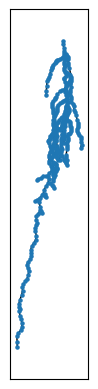

In [14]:
%run read.py
plot_mpl(dgs)

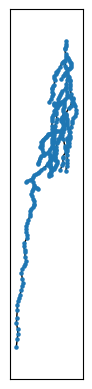

In [26]:
%run read.py
plot_mpl_mtg(gs[4])

# Compute hydraulic

In [21]:
from openalea.hydroroot.hydro_io import import_rsml_to_discrete_mtg, export_mtg_to_rsml

In [23]:
resolution = 1./(416*100) # 416 pixels per cm

In [24]:
import openalea.rsml